# 02 - Pré-processamento: log-Mel e ruído

Parte 1 do projeto. A partir do `dados/subconjunto/divisoes.csv` (notebook 01):

1. cada gravação vira até 12 janelas de 5 s (passo 2,5 s); janelas 20 dB mais fracas que a mais forte da gravação são descartadas (rótulo fraco);
2. cada janela vira um log-Mel de 128 bandas (32 kHz, 50-14000 Hz, `n_fft` 2048, `hop` 512 → 128 × 313), em dB com referência fixa;
3. os ruídos da ESC-50 (folds 1-4) viram log-Mel para o aumento por ruído no treino;
4. o conjunto de teste é refeito com ruído do fold 5 da ESC-50, misturado na forma de onda a 20, 10, 5 e 0 dB (E3).

Saída em `dados/espectrogramas/mel128_32k/` (fora do git; ~3 GB). No Colab, rode uma vez e deixe no Drive.

In [1]:
# Preparação no Colab (no computador local, rode a partir da raiz do repositório)
import sys, os
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/birdclef-dl"):
        !git clone -q https://github.com/arbcaio/birdclef-dl.git /content/birdclef-dl
    %cd /content/birdclef-dl
    !pip install -q -e .
    DRIVE = "/content/drive/MyDrive/birdclef-dl/dados"
    for sub in ["bruto", "ruido", "subconjunto", "espectrogramas"]:
        if not os.path.exists(f"dados/{sub}") and os.path.exists(f"{DRIVE}/{sub}"):
            !ln -s {DRIVE}/{sub} dados/{sub}
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from birdclef import dados, preproc, aumento

cfg = preproc.MEL128_32K
div = pd.read_csv(dados.pasta_dados() / "subconjunto" / "divisoes.csv")
pasta = preproc.pasta_config(cfg)
if not (pasta / "X.npy").exists():
    preproc.preprocessar(div, cfg)
if not (pasta / "R.npy").exists():
    aumento.preparar_ruido_treino(cfg)
if not (pasta / "janelas_teste.csv").exists():
    aumento.preparar_teste_ruidoso(cfg)
X, janelas = preproc.carregar(cfg)
print("X:", X.shape, X.dtype, f"{X.nbytes / 2**30:.2f} GiB")

X: (23635, 128, 313) float16 1.76 GiB


## Janelas por gravação e por partição

In [3]:
por_grav = janelas.groupby("filename").size()
print(por_grav.describe().round(2).to_string())
pd.crosstab(janelas["primary_label"], [janelas["particao"], janelas["fold"]], margins=True)

count    3000.00
mean        7.88
std         4.22
min         1.00
25%         4.00
50%         9.00
75%        12.00
max        12.00


particao      teste treino                            All
fold             -1      0     1     2     3     4       
primary_label                                            
banana          238    210   204   196   212   223   1283
blbgra1         251    209   206   199   237   223   1325
bobfly1         242    150   197   129   181   204   1103
bubwre1         241    184   170   210   196   231   1232
butsal1         239    197   189   212   238   239   1314
compau          292    268   226   208   214   232   1440
greegr           92    150    67    61   106   116    592
grekis          213    146   170   144   185   177   1035
roahaw          249    219   205   243   190   210   1316
sobtyr1         245    168   155   151   166   156   1041
socfly1         187    190   176   180   190   166   1089
soulap1         224    163   159   132   170   138    986
strcuc1         269    213   197   217   182   233   1311
strfly1         222    160   208   168   197   200   1155
trokin          211    126   199   177   171   209   1093
tropar          255    195   193   178   126   179   1126
wbwwre1         284    199   211   195   189   194   1272
whtdov          302    193   235   229   234   213   1406
yeofly1         216    182   172   193   163   172   1098
yercac1         300    231   206   220   240   221   1418
All            4772   3753  3745  3642  3787  3936  23635

## Exemplos de log-Mel (limpo e com ruído)

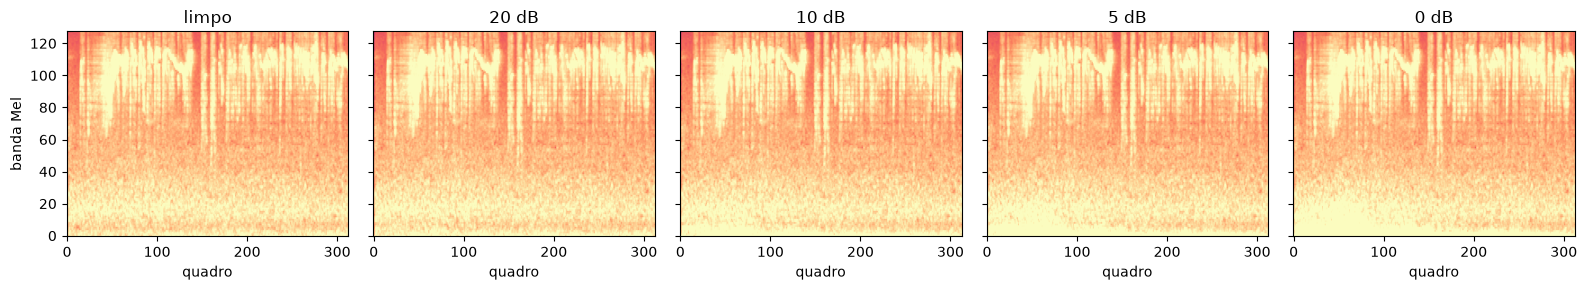

In [4]:
jt = pd.read_csv(pasta / "janelas_teste.csv")
i = 0
versoes = {"limpo": np.asarray(X[np.flatnonzero((janelas.particao == "teste").to_numpy())[i]])}
for snr in aumento.SNRS_TESTE:
    versoes[f"{snr} dB"] = np.load(pasta / f"X_teste_snr{snr}.npy", mmap_mode="r")[i]
fig, ax = plt.subplots(1, len(versoes), figsize=(16, 3), sharey=True)
for a, (nome, m) in zip(ax, versoes.items()):
    a.imshow(m.astype(np.float32), origin="lower", aspect="auto", cmap="magma", vmin=-100, vmax=0)
    a.set_title(nome); a.set_xlabel("quadro")
ax[0].set_ylabel("banda Mel")
fig.tight_layout(); fig.savefig("resultados/eda/logmel_ruido.png", dpi=130)